<a href="https://colab.research.google.com/github/Intanarumm/Visualisasi_Data/blob/main/Analisis%26Visualisasi_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 300

kategori = ['Elektronik', 'Fashion', 'Makanan', 'Kecantikan', 'Olahraga']
harga = {'Elektronik': 500000, 'Fashion': 150000, 'Makanan': 40000,
         'Kecantikan': 90000, 'Olahraga': 200000}

df = pd.DataFrame({
    'tanggal': pd.date_range('2025-01-01', periods=n, freq='D'),
    'kategori_produk': np.random.choice(kategori, n),
    'jumlah': np.random.randint(1, 6, n),
    'rating_pelanggan': np.random.choice([1, 2, 3, 4, 5], n, p=[0.05, 0.1, 0.2, 0.35, 0.3]),
    'wilayah': np.random.choice(['Jawa', 'Sumatera', 'Kalimantan', 'Sulawesi'], n)
})

# beberapa outlier (pembelian reseller)
df.loc[np.random.choice(n, 5, replace=False), 'jumlah'] = 30
df['total'] = df['jumlah'] * df['kategori_produk'].map(harga)

df.to_csv('penjualan_nusantaramart.csv', index=False)
print("File berhasil dibuat!")

File berhasil dibuat!


In [2]:
import pandas as pd

df = pd.read_csv('penjualan_nusantaramart.csv')

print(df['total'].mean())             # rata-rata
print(df['total'].median())           # median
print(df['total'].std())              # standar deviasi
print(df['total'].quantile(0.25))     # Q1
print(df['total'].quantile(0.75))     # Q3

print(df.describe())                  # ringkasan statistik seluruh kolom numerik

672800.0
400000.0
745019.6917780924
180000.0
1000000.0
           jumlah  rating_pelanggan         total
count  300.000000        300.000000  3.000000e+02
mean     3.553333          3.746667  6.728000e+05
std      3.744403          1.089240  7.450197e+05
min      1.000000          1.000000  4.000000e+04
25%      2.000000          3.000000  1.800000e+05
50%      3.000000          4.000000  4.000000e+05
75%      5.000000          5.000000  1.000000e+06
max     30.000000          5.000000  4.500000e+06


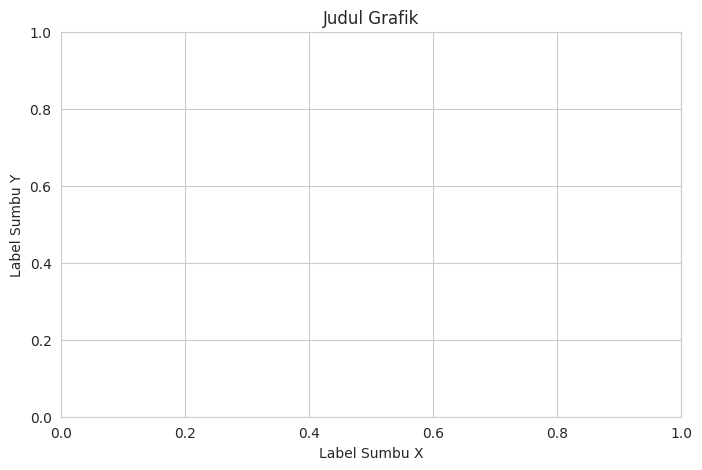

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.figure(figsize=(8, 5))
# ... perintah membuat grafik ...
plt.title('Judul Grafik')
plt.xlabel('Label Sumbu X')
plt.ylabel('Label Sumbu Y')
plt.show()

*Tugas Analisis 1* (Eksplorasi Data & Statistika Deskriptif)
1. Kategori produk apa yang memiliki rata-rata nilai transaksi (total) tertinggi?
2. Apakah ada kolom yang memiliki data kosong (missing value)? Bagaimana cara mengeceknya dari output df.info()?
3. Bandingkan nilai mean dan median kolom total secara keseluruhan. Apa yang bisa kamu simpulkan tentang sebaran datanya?

In [4]:
import pandas as pd

df = pd.read_csv('penjualan_nusantaramart.csv')
print(df.head())        # lihat 5 baris pertama
print(df.info())        # tipe data & jumlah data kosong
print(df.describe())    # ringkasan statistik

# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

      tanggal kategori_produk  jumlah  rating_pelanggan     wilayah    total
0  2025-01-01      Kecantikan       5                 5        Jawa   450000
1  2025-01-02        Olahraga       5                 2        Jawa  1000000
2  2025-01-03         Makanan       1                 4  Kalimantan    40000
3  2025-01-04        Olahraga       5                 5    Sulawesi  1000000
4  2025-01-05        Olahraga       3                 4    Sulawesi   600000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   tanggal           300 non-null    object
 1   kategori_produk   300 non-null    object
 2   jumlah            300 non-null    int64 
 3   rating_pelanggan  300 non-null    int64 
 4   wilayah           300 non-null    object
 5   total             300 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 14.2+ KB
None
          

*JAWABAN*
1. Kategori dengan rata-rata transaksi tertinggi adalah Elektronik (±Rp 1.528.986).
2. Tidak ada data kosong. Pada df.info(), semua kolom memiliki 300 non-null, sama dengan jumlah baris (300 entries).
3. Mean (Rp 672.800) lebih besar dari median (Rp 400.000), sehingga sebaran data miring ke kanan akibat adanya transaksi bernilai sangat tinggi (outlier). Median lebih tepat untuk mewakili nilai transaksi umum.

*Tugas Analisis 2* (Bar Chart)
1. Kategori apa yang menyumbang penjualan tertinggi dan terendah?
2. Menurutmu, apa rekomendasi bisnis yang bisa diberikan kepada manajer Nusantara Mart berdasarkan grafik ini?

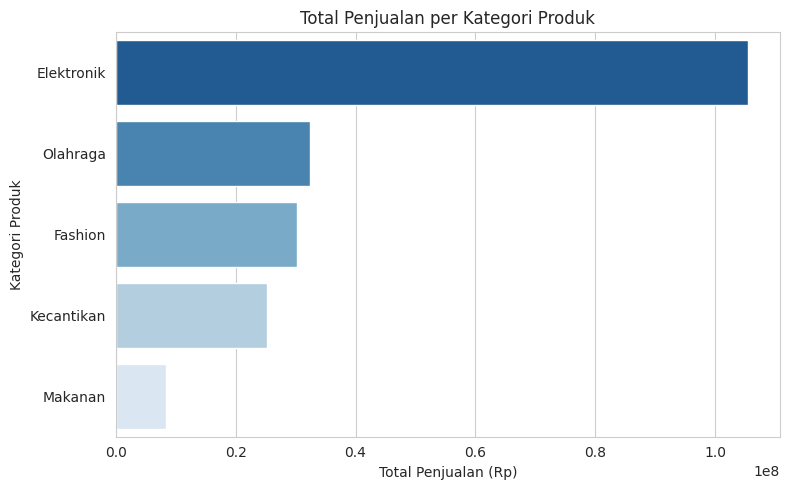

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index,
            hue=total_kategori.index, palette='Blues_r', legend=False)
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

In [15]:
print(total_kategori)

kategori_produk
Elektronik    105500000
Olahraga       32400000
Fashion        30300000
Kecantikan     25200000
Makanan         8440000
Name: total, dtype: int64


*JAWABAN*
1. Kategori dengan penjualan tertinggi adalah Elektronik (±Rp 105 juta), sedangkan yang terendah adalah Makanan (±Rp 8 juta).
2. anajer sebaiknya menambah stok dan promosi untuk Elektronik karena kontribusinya paling besar, memberi promo atau bundling pada kategori berpenjualan rendah seperti Makanan, serta mengurangi ketergantungan pada satu kategori dengan mendorong penjualan kategori lain.

*Tugas Analisis 3* (Line Chart)
1. Bulan apa yang memiliki penjualan tertinggi? Menurutmu, apa kemungkinan penyebabnya?
2. Apakah tren penjualan cenderung naik, turun, atau fluktuatif? Jelaskan.

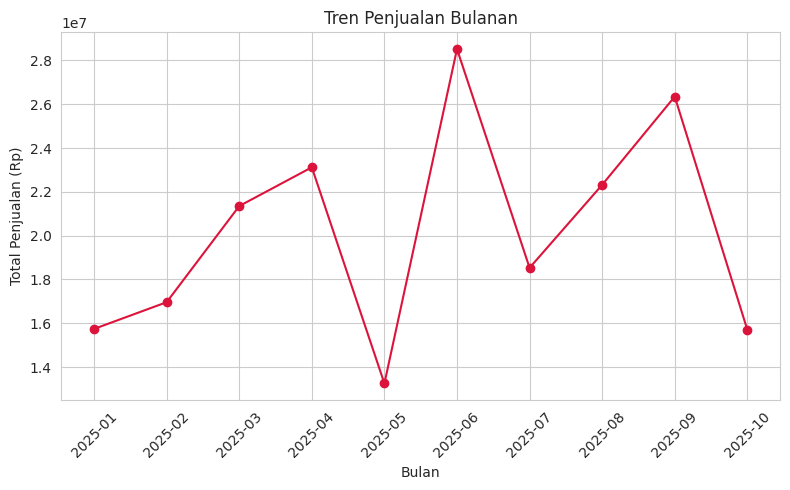

In [6]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

tren_bulanan = df.groupby('bulan')['total'].sum()

plt.figure(figsize=(8, 5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values,
         marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
print(tren_bulanan)
print("Tertinggi:", tren_bulanan.idxmax(), f"(Rp {tren_bulanan.max():,.0f})")
print("Terendah :", tren_bulanan.idxmin(), f"(Rp {tren_bulanan.min():,.0f})")

bulan
2025-01    15740000
2025-02    16960000
2025-03    21350000
2025-04    23120000
2025-05    13250000
2025-06    28520000
2025-07    18530000
2025-08    22320000
2025-09    26350000
2025-10    15700000
Freq: M, Name: total, dtype: int64
Tertinggi: 2025-06 (Rp 28,520,000)
Terendah : 2025-05 (Rp 13,250,000)


*JAWABAN*
1. Bulan dengan penjualan tertinggi adalah Juni 2025 (±Rp 28,5 juta). Kemungkinan penyebabnya adalah musim libur sekolah, adanya promo pertengahan tahun, atau pembelian dalam jumlah besar oleh reseller.
2. Tren penjualan cenderung fluktuatif karena naik turun bergantian. Naik dari Januari sampai April, turun tajam di Mei, naik ke puncak di Juni, lalu kembali turun dan naik di bulan-bulan berikutnya.

*Tugas Analisis 4* (Scatter Plot)
1. Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi? Jelaskan hubungan tersebut (positif/negatif/tidak berhubungan).
2. Apakah ada titik data yang terlihat jauh dari pola umum (kemungkinan outlier)? Sebutkan kategorinya jika terlihat dari warna.

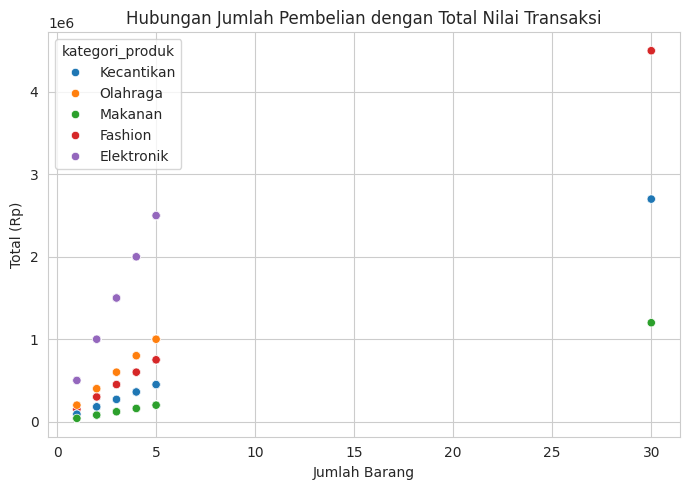

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

In [13]:
print(df[['jumlah', 'total']].corr())

          jumlah     total
jumlah  1.000000  0.554576
total   0.554576  1.000000


In [12]:
print(df[df['jumlah'] >= 30][['kategori_produk', 'jumlah', 'total']])

    kategori_produk  jumlah    total
20          Fashion      30  4500000
160         Makanan      30  1200000
166      Kecantikan      30  2700000
204      Kecantikan      30  2700000
260         Fashion      30  4500000


*JAWABAN*
1. Terdapat hubungan positif antara jumlah barang dan total nilai transaksi, semakin banyak barang yang dibeli, semakin besar total transaksinya. Kemiringan tiap kategori berbeda karena harga satuannya berbeda (Elektronik paling curam).
2. Ada outlier pada jumlah 30, yaitu kategori Fashion (merah), Kecantikan (biru), dan Makanan (hijau). Kemungkinan penyebabnya adalah pembelian dalam jumlah besar oleh reseller atau kesalahan input data.

*Tugas Analisis 5* (Histogram & Boxplot)
1. Bagaimana bentuk distribusi rating pelanggan? Apakah cenderung tinggi, rendah, atau merata?
2. Kategori produk mana yang memiliki titik-titik di luar kotak boxplot (outlier)? Apa kemungkinan penyebabnya (misalnya pembelian oleh reseller)?

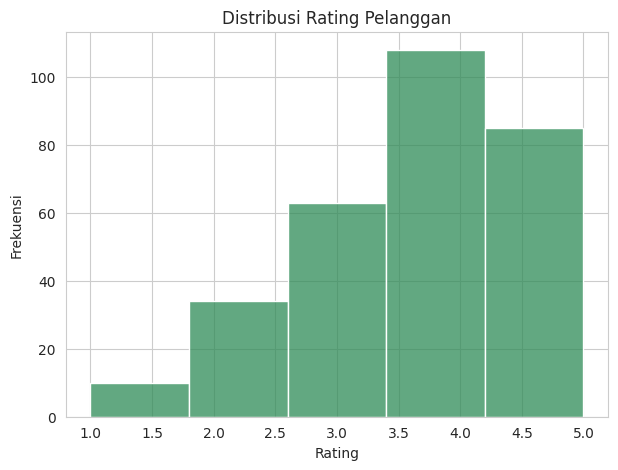

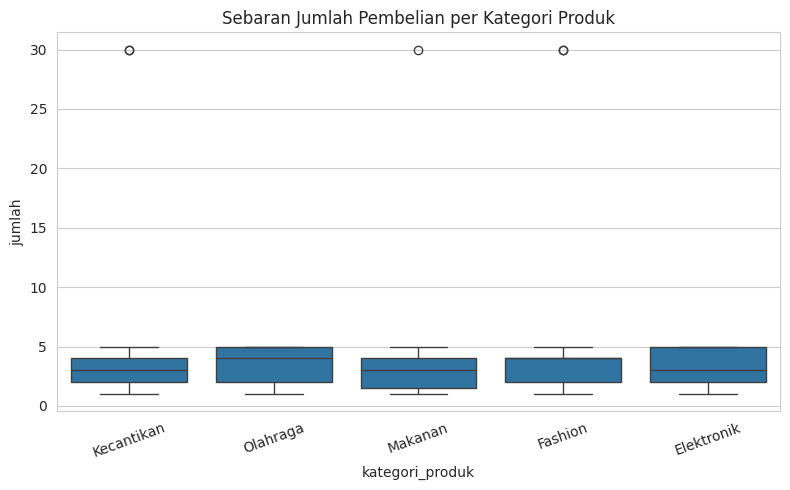

In [8]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7, 5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:
print(df['rating_pelanggan'].value_counts().sort_index())
print("Rata-rata rating:", df['rating_pelanggan'].mean())

rating_pelanggan
1     10
2     34
3     63
4    108
5     85
Name: count, dtype: int64
Rata-rata rating: 3.7466666666666666


In [9]:
for kat, grup in df.groupby('kategori_produk'):
    Q1 = grup['jumlah'].quantile(0.25)
    Q3 = grup['jumlah'].quantile(0.75)
    IQR = Q3 - Q1
    batas_atas = Q3 + 1.5 * IQR
    out = grup[grup['jumlah'] > batas_atas]
    print(f"{kat}: batas atas = {batas_atas}, jumlah outlier = {len(out)}")

Elektronik: batas atas = 9.5, jumlah outlier = 0
Fashion: batas atas = 7.0, jumlah outlier = 2
Kecantikan: batas atas = 7.0, jumlah outlier = 2
Makanan: batas atas = 7.75, jumlah outlier = 1
Olahraga: batas atas = 9.5, jumlah outlier = 0


*JAWABAN*
1. Distribusi rating pelanggan cenderung tinggi (miring ke kiri). Frekuensi terbanyak ada di rating 4, disusul rating 5, sedangkan rating 1-2 jarang muncul. Artinya sebagian besar pelanggan puas.
2. Kategori yang memiliki outlier adalah Kecantikan, Makanan, dan Fashion (jumlah pembelian 30, jauh di atas normal 1-5). Kemungkinan penyebabnya adalah pembelian dalam jumlah besar oleh reseller atau kesalahan input data.

*Tugas Analisis 6* (Dashboard)
1. Menurutmu, apa keuntungan menyajikan beberapa grafik dalam satu dashboard dibandingkan grafik terpisah-pisah?
2. Jika kamu adalah manajer Nusantara Mart, keputusan bisnis apa yang akan kamu ambil setelah melihat dashboard ini?

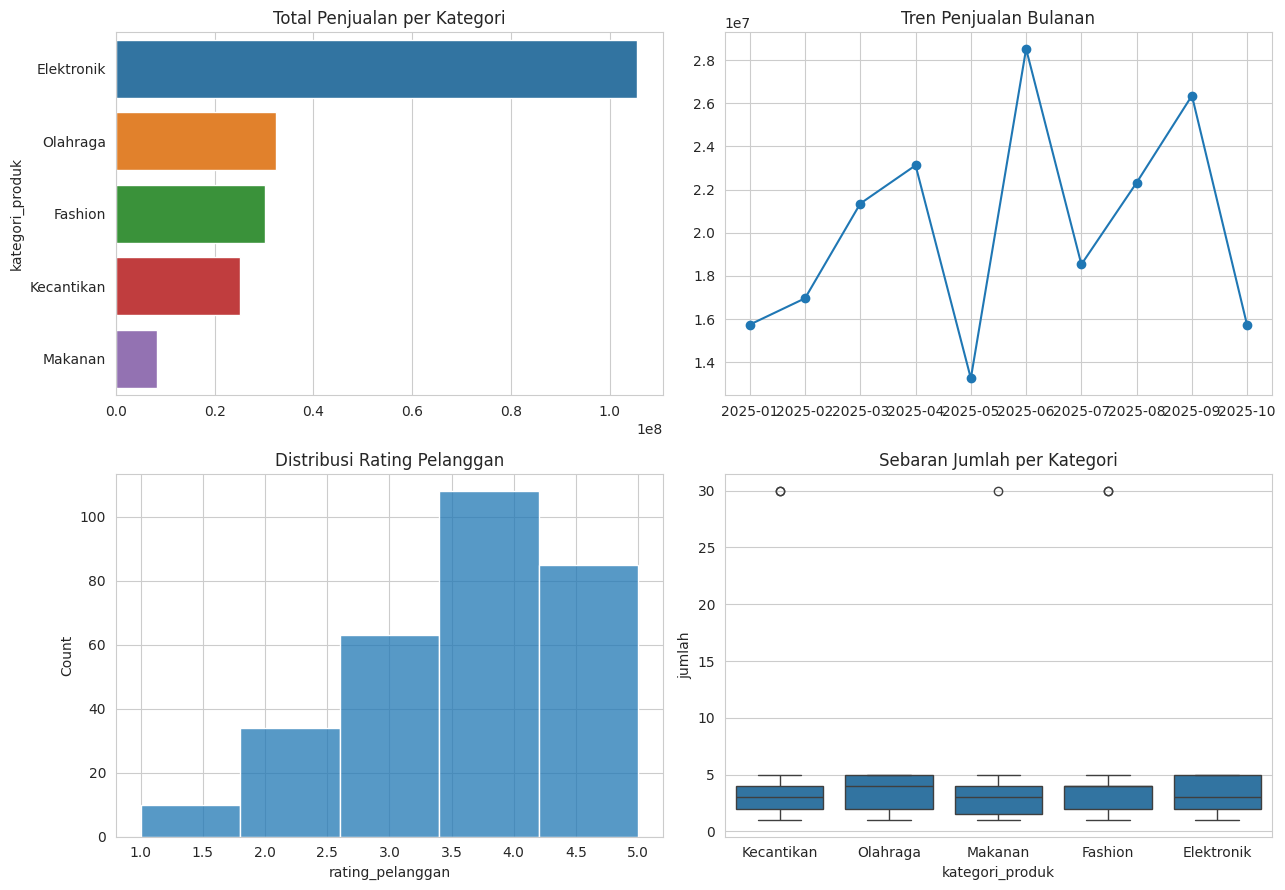

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=total_kategori.values, y=total_kategori.index,
            hue=total_kategori.index, legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Total Penjualan per Kategori')

axes[0, 1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0, 1].set_title('Tren Penjualan Bulanan')

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Rating Pelanggan')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1])
axes[1, 1].set_title('Sebaran Jumlah per Kategori')

plt.tight_layout()
plt.show()

*JAWABAN*
1. Keuntungan dashboard adalah seluruh informasi penting dapat dilihat sekaligus dalam satu tampilan, sehingga lebih ringkas, mudah dibandingkan dan dihubungkan antar-grafik, serta mempercepat pengambilan keputusan dan presentasi kepada manajemen.
2. Sebagai manajer, saya akan menambah stok dan promosi kategori Elektronik karena penjualannya paling tinggi, memberi promo atau bundling pada kategori berpenjualan rendah seperti Makanan, menyiapkan promo di bulan yang penjualannya turun (Mei, Juli, Oktober), mempertahankan kualitas layanan karena rating pelanggan tinggi, serta menyelidiki transaksi bernilai jumlah 30 yang tidak wajar, misalnya dengan membuat program harga grosir jika berasal dari reseller.

Tambahan untuk Proyek Integrasi (Bagian D)

In [16]:
# Cek data kosong dan dduplikat

print(df.isnull().sum())          # jumlah data kosong per kolom
print(df.duplicated().sum())      # jumlah baris duplikat
df = df.drop_duplicates()         # hapus duplikat

tanggal             0
kategori_produk     0
jumlah              0
rating_pelanggan    0
wilayah             0
total               0
bulan               0
dtype: int64
0


In [17]:
# Deteksi outlier dengan aturan IQR
Q1 = df['jumlah'].quantile(0.25)
Q3 = df['jumlah'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = df[(df['jumlah'] < batas_bawah) | (df['jumlah'] > batas_atas)]
print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Batas: {batas_bawah} s/d {batas_atas}")
print(outlier)

Q1=2.0, Q3=5.0, IQR=3.0
Batas: -2.5 s/d 9.5
       tanggal kategori_produk  jumlah  rating_pelanggan   wilayah    total  \
20  2025-01-21         Fashion      30                 4  Sumatera  4500000   
160 2025-06-10         Makanan      30                 4      Jawa  1200000   
166 2025-06-16      Kecantikan      30                 3  Sulawesi  2700000   
204 2025-07-24      Kecantikan      30                 5      Jawa  2700000   
260 2025-09-18         Fashion      30                 5  Sumatera  4500000   

       bulan  
20   2025-01  
160  2025-06  
166  2025-06  
204  2025-07  
260  2025-09  


In [18]:
# Ringkasan Statistik dan Laporan
print("=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===")
print(f"Total Penjualan     : Rp {df['total'].sum():,.0f}")
print(f"Rata-rata Transaksi : Rp {df['total'].mean():,.0f}")
print(f"Kategori Terlaris   : {df.groupby('kategori_produk')['total'].sum().idxmax()}")
print(f"Wilayah Teratas     : {df.groupby('wilayah')['total'].sum().idxmax()}")
print(f"Rating Rata-rata    : {df['rating_pelanggan'].mean():.2f} / 5")

=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===
Total Penjualan     : Rp 201,840,000
Rata-rata Transaksi : Rp 672,800
Kategori Terlaris   : Elektronik
Wilayah Teratas     : Kalimantan
Rating Rata-rata    : 3.75 / 5
